In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!mkdir -p /content/m100
!tar -xf /content/drive/MyDrive/0.tar -C /content/m100
!ls /content/m100 | head

10.parquet
11.parquet
13.parquet
14.parquet
16.parquet
17.parquet
18.parquet
19.parquet
2.parquet
3.parquet


In [ ]:
import pandas as pd, glob
files = glob.glob('/content/m100/**/*.parquet', recursive=True)
print(len(files), "node files")
df = pd.read_parquet(files[0])
print(df.shape)
print(df.columns.tolist())
df.head()

16 node files
(72944, 354)
['timestamp', 'ambient_avg', 'ambient_std', 'ambient_min', 'ambient_max', 'dimm0_temp_avg', 'dimm0_temp_std', 'dimm0_temp_min', 'dimm0_temp_max', 'dimm10_temp_avg', 'dimm10_temp_std', 'dimm10_temp_min', 'dimm10_temp_max', 'dimm11_temp_avg', 'dimm11_temp_std', 'dimm11_temp_min', 'dimm11_temp_max', 'dimm12_temp_avg', 'dimm12_temp_std', 'dimm12_temp_min', 'dimm12_temp_max', 'dimm13_temp_avg', 'dimm13_temp_std', 'dimm13_temp_min', 'dimm13_temp_max', 'dimm14_temp_avg', 'dimm14_temp_std', 'dimm14_temp_min', 'dimm14_temp_max', 'dimm15_temp_avg', 'dimm15_temp_std', 'dimm15_temp_min', 'dimm15_temp_max', 'dimm1_temp_avg', 'dimm1_temp_std', 'dimm1_temp_min', 'dimm1_temp_max', 'dimm2_temp_avg', 'dimm2_temp_std', 'dimm2_temp_min', 'dimm2_temp_max', 'dimm3_temp_avg', 'dimm3_temp_std', 'dimm3_temp_min', 'dimm3_temp_max', 'dimm4_temp_avg', 'dimm4_temp_std', 'dimm4_temp_min', 'dimm4_temp_max', 'dimm5_temp_avg', 'dimm5_temp_std', 'dimm5_temp_min', 'dimm5_temp_max', 'dimm6_temp

,timestamp,ambient_avg,ambient_std,ambient_min,ambient_max,dimm0_temp_avg,dimm0_temp_std,dimm0_temp_min,dimm0_temp_max,dimm10_temp_avg,...,ps1_output_curre_max,ps1_output_volta_avg,ps1_output_volta_std,ps1_output_volta_min,ps1_output_volta_max,total_power_avg,total_power_std,total_power_min,total_power_max,value
0,2020-03-09 12:00:00+00:00,20.025000,0.139195,19.799999,20.200001,27.0,0.0,27.0,27.0,29.0,...,22.0,12.390625,0.029148,12.3,12.4,360.0,0.0,360.0,360.0,<NA>
1,2020-03-09 12:15:00+00:00,19.900000,0.141422,19.799999,20.200001,27.0,0.0,27.0,27.0,29.0,...,24.0,12.390625,0.029148,12.3,12.4,360.0,0.0,360.0,360.0,<NA>
2,2020-03-09 12:30:00+00:00,19.862856,0.092847,19.799999,20.000000,27.0,0.0,27.0,27.0,29.0,...,22.0,12.385713,0.034993,12.3,12.4,360.0,0.0,360.0,360.0,<NA>
3,2020-03-09 12:45:00+00:00,20.000000,0.000000,20.000000,20.000000,27.0,0.0,27.0,27.0,29.0,...,23.0,12.383332,0.037268,12.3,12.4,360.0,0.0,360.0,360.0,<NA>
4,2020-03-09 13:00:00+00:00,19.964444,0.076465,19.799999,20.000000,27.0,0.0,27.0,27.0,29.0,...,23.0,12.391112,0.028458,12.3,12.4,360.0,0.0,360.0,360.0,<NA>


In [ ]:
print("LABEL:", [c for c in df.columns if 'label' in c.lower() or 'anomal' in c.lower()])
print("TEMP:", [c for c in df.columns if 'temp' in c.lower()][:20])
print("FAN:", [c for c in df.columns if 'fan' in c.lower()][:20])
print("POWER:", [c for c in df.columns if 'power' in c.lower() or 'pwr' in c.lower()][:20])

LABEL: []
TEMP: ['dimm0_temp_avg', 'dimm0_temp_std', 'dimm0_temp_min', 'dimm0_temp_max', 'dimm10_temp_avg', 'dimm10_temp_std', 'dimm10_temp_min', 'dimm10_temp_max', 'dimm11_temp_avg', 'dimm11_temp_std', 'dimm11_temp_min', 'dimm11_temp_max', 'dimm12_temp_avg', 'dimm12_temp_std', 'dimm12_temp_min', 'dimm12_temp_max', 'dimm13_temp_avg', 'dimm13_temp_std', 'dimm13_temp_min', 'dimm13_temp_max']
FAN: ['fan0_0_avg', 'fan0_0_std', 'fan0_0_min', 'fan0_0_max', 'fan0_1_avg', 'fan0_1_std', 'fan0_1_min', 'fan0_1_max', 'fan1_0_avg', 'fan1_0_std', 'fan1_0_min', 'fan1_0_max', 'fan1_1_avg', 'fan1_1_std', 'fan1_1_min', 'fan1_1_max', 'fan2_0_avg', 'fan2_0_std', 'fan2_0_min', 'fan2_0_max']
POWER: ['fan_disk_power_avg', 'fan_disk_power_std', 'fan_disk_power_min', 'fan_disk_power_max', 'p0_io_power_avg', 'p0_io_power_std', 'p0_io_power_min', 'p0_io_power_max', 'p0_mem_power_avg', 'p0_mem_power_std', 'p0_mem_power_min', 'p0_mem_power_max', 'p0_power_avg', 'p0_power_std', 'p0_power_min', 'p0_power_max', 'p1_i

In [ ]:
odd = [c for c in df.columns if not c.endswith(('_avg','_std','_min','_max'))]
print(odd)

['timestamp', 'value']


In [ ]:
print(df['value'].dtype)
print(df['value'].value_counts(dropna=False))

Int32
value
2       26660
<NA>    24307
0       17088
3        4889
Name: count, dtype: Int64


In [ ]:
import pandas as pd
rows = []
for f in files:
    d = pd.read_parquet(f, columns=['timestamp', 'value'])
    rows.append((f.split('/')[-1], len(d), d['value'].value_counts(dropna=False).to_dict()))
for r in rows:
    print(r)

('3.parquet', 72944, {np.int32(2): 26660, <NA>: 24307, np.int32(0): 17088, np.int32(3): 4889})
('19.parquet', 81847, {np.int32(0): 51639, np.int32(2): 20950, <NA>: 9253, np.int32(3): 5})
('4.parquet', 82403, {np.int32(0): 31308, <NA>: 27205, np.int32(2): 16084, np.int32(3): 7806})
('7.parquet', 83920, {np.int32(0): 73195, <NA>: 9365, np.int32(2): 1355, np.int32(3): 5})
('14.parquet', 83925, {np.int32(0): 73243, <NA>: 9370, np.int32(2): 1307, np.int32(3): 5})
('6.parquet', 82604, {np.int32(0): 31899, <NA>: 27406, np.int32(2): 15493, np.int32(3): 7806})
('11.parquet', 83919, {np.int32(0): 73824, <NA>: 9367, np.int32(2): 723, np.int32(3): 5})
('5.parquet', 75952, {np.int32(0): 31423, <NA>: 20754, np.int32(2): 15969, np.int32(3): 7806})
('8.parquet', 83922, {np.int32(0): 73411, <NA>: 9367, np.int32(2): 1139, np.int32(3): 5})
('18.parquet', 83923, {np.int32(0): 67246, <NA>: 9367, np.int32(2): 7304, np.int32(3): 6})
('10.parquet', 83923, {np.int32(0): 73101, <NA>: 9369, np.int32(2): 1448, np

In [ ]:
d = pd.read_parquet('/content/m100/11.parquet')
avg_cols = [c for c in d.columns if c.endswith('_avg')]

normal = d[d['value'] == 0][avg_cols]
crit = d[d['value'] == 2][avg_cols]

# how many separate alert episodes are there?
is2 = (d['value'] == 2).fillna(False).astype(int)
episodes = (is2.diff() == 1).sum()
print("critical rows:", int(is2.sum()), "| separate episodes:", int(episodes))

# which signals differ most between normal and critical (in standard deviations)?
std = normal.std().replace(0, float('nan'))
diff = ((crit.mean() - normal.mean()) / std).abs().sort_values(ascending=False)
print(diff.head(15))

critical rows: 723 | separate episodes: 121
ps0_output_volta_avg    11.224474
fan1_1_avg               8.032714
fan2_1_avg               7.409633
fan1_0_avg               7.273087
fan3_1_avg               7.223215
fan3_0_avg               6.825944
fan2_0_avg               6.709393
fan0_1_avg               6.610163
fan0_0_avg               6.154399
ps1_output_volta_avg     5.814395
p0_vdd_temp_avg          2.657080
p1_vdd_temp_avg          2.608700
ps1_input_power_avg      2.350946
ps1_output_curre_avg     2.054316
ps0_input_power_avg      1.314955
dtype: float64


In [ ]:
print(len(avg_cols))
print(avg_cols)

88
['ambient_avg', 'dimm0_temp_avg', 'dimm10_temp_avg', 'dimm11_temp_avg', 'dimm12_temp_avg', 'dimm13_temp_avg', 'dimm14_temp_avg', 'dimm15_temp_avg', 'dimm1_temp_avg', 'dimm2_temp_avg', 'dimm3_temp_avg', 'dimm4_temp_avg', 'dimm5_temp_avg', 'dimm6_temp_avg', 'dimm7_temp_avg', 'dimm8_temp_avg', 'dimm9_temp_avg', 'fan0_0_avg', 'fan0_1_avg', 'fan1_0_avg', 'fan1_1_avg', 'fan2_0_avg', 'fan2_1_avg', 'fan3_0_avg', 'fan3_1_avg', 'fan_disk_power_avg', 'gpu0_core_temp_avg', 'gpu0_mem_temp_avg', 'gpu1_core_temp_avg', 'gpu1_mem_temp_avg', 'gpu3_core_temp_avg', 'gpu3_mem_temp_avg', 'gpu4_core_temp_avg', 'gpu4_mem_temp_avg', 'gv100card0_avg', 'gv100card1_avg', 'gv100card3_avg', 'gv100card4_avg', 'p0_core10_temp_avg', 'p0_core11_temp_avg', 'p0_core12_temp_avg', 'p0_core13_temp_avg', 'p0_core14_temp_avg', 'p0_core15_temp_avg', 'p0_core16_temp_avg', 'p0_core17_temp_avg', 'p0_core22_temp_avg', 'p0_core23_temp_avg', 'p0_core4_temp_avg', 'p0_core5_temp_avg', 'p0_core6_temp_avg', 'p0_core7_temp_avg', 'p0_c

In [1]:
import pandas as pd, numpy as np

nodes = [7, 8, 9, 10, 11, 13, 14, 16, 17]

def mean_of(d, prefix, suffix):
    cols = [c for c in d.columns if c.startswith(prefix) and c.endswith(suffix)]
    return d[cols].mean(axis=1) if cols else np.nan

def reduce_node(n):
    d = pd.read_parquet(f'/content/m100/{n}.parquet')
    g = lambda c: d[c] if c in d.columns else np.nan   # skip safely if missing
    out = pd.DataFrame({'timestamp': d['timestamp'], 'node': n, 'label': d['value']})
    out['ambient'] = g('ambient_avg')
    for i in range(4):
        for j in range(2):
            out[f'fan{i}_{j}'] = g(f'fan{i}_{j}_avg')
    out['fan_disk_power'] = g('fan_disk_power_avg')
    out['p0_vdd_temp'] = g('p0_vdd_temp_avg')
    out['p1_vdd_temp'] = g('p1_vdd_temp_avg')
    out['dimm_temp'] = mean_of(d, 'dimm', '_temp_avg')
    out['p0_core_temp'] = mean_of(d, 'p0_core', '_temp_avg')
    out['p1_core_temp'] = mean_of(d, 'p1_core', '_temp_avg')
    out['gpu_core_temp'] = mean_of(d, 'gpu', 'core_temp_avg')
    out['gpu_mem_temp'] = mean_of(d, 'gpu', 'mem_temp_avg')
    for c in ['p0_power', 'p1_power', 'total_power', 'ps0_input_power', 'ps1_input_power']:
        out[c] = g(f'{c}_avg')
    feat = out.columns.difference(['timestamp', 'node', 'label'])
    out[feat] = out[feat].astype('float32')
    return out

df = pd.concat([reduce_node(n) for n in nodes], ignore_index=True)
df.to_parquet('/content/drive/MyDrive/m100_reduced.parquet')

print(df.shape)
feat = [c for c in df.columns if c not in ('timestamp', 'node', 'label')]
print("features:", len(feat))
print("label counts:\n", df['label'].value_counts(dropna=False))
print("missing % per column:\n", (df[feat].isna().mean() * 100).round(1).sort_values(ascending=False).head(10))
print("constant columns:", [c for c in feat if df[c].nunique() <= 1])

FileNotFoundError: [Errno 2] No such file or directory: '/content/m100/7.parquet'

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/m100
!tar -xf /content/drive/MyDrive/0.tar -C /content/m100
!ls /content/m100

Mounted at /content/drive
10.parquet  14.parquet	18.parquet  3.parquet  6.parquet  9.parquet
11.parquet  16.parquet	19.parquet  4.parquet  7.parquet
13.parquet  17.parquet	2.parquet   5.parquet  8.parquet


In [3]:
import os
for n in [7, 8, 9, 10, 11, 13, 14, 16, 17]:
    print(n, os.path.exists(f'/content/m100/{n}.parquet'))

7 True
8 True
9 True
10 True
11 True
13 True
14 True
16 True
17 True


In [4]:
import pandas as pd, numpy as np

nodes = [7, 8, 9, 10, 11, 13, 14, 16, 17]

def mean_of(d, prefix, suffix):
    cols = [c for c in d.columns if c.startswith(prefix) and c.endswith(suffix)]
    return d[cols].mean(axis=1) if cols else np.nan

def reduce_node(n):
    d = pd.read_parquet(f'/content/m100/{n}.parquet')
    g = lambda c: d[c] if c in d.columns else np.nan   # skip safely if missing
    out = pd.DataFrame({'timestamp': d['timestamp'], 'node': n, 'label': d['value']})
    out['ambient'] = g('ambient_avg')
    for i in range(4):
        for j in range(2):
            out[f'fan{i}_{j}'] = g(f'fan{i}_{j}_avg')
    out['fan_disk_power'] = g('fan_disk_power_avg')
    out['p0_vdd_temp'] = g('p0_vdd_temp_avg')
    out['p1_vdd_temp'] = g('p1_vdd_temp_avg')
    out['dimm_temp'] = mean_of(d, 'dimm', '_temp_avg')
    out['p0_core_temp'] = mean_of(d, 'p0_core', '_temp_avg')
    out['p1_core_temp'] = mean_of(d, 'p1_core', '_temp_avg')
    out['gpu_core_temp'] = mean_of(d, 'gpu', 'core_temp_avg')
    out['gpu_mem_temp'] = mean_of(d, 'gpu', 'mem_temp_avg')
    for c in ['p0_power', 'p1_power', 'total_power', 'ps0_input_power', 'ps1_input_power']:
        out[c] = g(f'{c}_avg')
    feat = out.columns.difference(['timestamp', 'node', 'label'])
    out[feat] = out[feat].astype('float32')
    return out

df = pd.concat([reduce_node(n) for n in nodes], ignore_index=True)
df.to_parquet('/content/drive/MyDrive/m100_reduced.parquet')

print(df.shape)
feat = [c for c in df.columns if c not in ('timestamp', 'node', 'label')]
print("features:", len(feat))
print("label counts:\n", df['label'].value_counts(dropna=False))
print("missing % per column:\n", (df[feat].isna().mean() * 100).round(1).sort_values(ascending=False).head(10))
print("constant columns:", [c for c in feat if df[c].nunique() <= 1])

(751363, 25)
features: 22
label counts:
 label
0       660172
<NA>     81715
2         9429
3           47
Name: count, dtype: Int64
missing % per column:
 gpu_mem_temp    8.0
ambient         7.9
fan0_1          7.9
fan1_0          7.9
fan1_1          7.9
fan0_0          7.9
fan2_0          7.9
fan2_1          7.9
fan3_1          7.9
fan3_0          7.9
dtype: float64
constant columns: []


In [5]:
df = df.sort_values(['node', 'timestamp']).reset_index(drop=True)
df['sensor_na'] = df['fan0_0'].isna()

# 1) do missing sensor rows line up with blank labels?
print(pd.crosstab(df['sensor_na'], df['label'].fillna(-1)))

# 2) how long are the gaps? (1 row = 15 minutes)
for n, g in df.groupby('node'):
    runs = (g['sensor_na'] != g['sensor_na'].shift()).cumsum()
    r = g['sensor_na'].groupby(runs).agg(['first', 'size'])
    r = r[r['first']]
    print(n, "gaps:", len(r), "| longest:", int(r['size'].max()) if len(r) else 0, "rows")

# 3) are readings exactly 15 minutes apart?
print(df.groupby('node')['timestamp'].apply(lambda t: t.diff().dropna().value_counts().head(2).to_dict()))

label         -1      0     2   3 
sensor_na                         
False      30839  652780  8695  47
True       50876    7392   734   0
7 gaps: 203 | longest: 2595 rows
8 gaps: 209 | longest: 2595 rows
9 gaps: 207 | longest: 2595 rows
10 gaps: 209 | longest: 2595 rows
11 gaps: 208 | longest: 2595 rows
13 gaps: 212 | longest: 2595 rows
14 gaps: 210 | longest: 2595 rows
16 gaps: 210 | longest: 909 rows
17 gaps: 211 | longest: 2595 rows
node                 
7     0 days 00:15:00    83914
      0 days 09:30:00        1
8     0 days 00:15:00    83916
      0 days 09:30:00        1
9     0 days 00:15:00    83917
      0 days 09:30:00        1
10    0 days 00:15:00    83917
      0 days 09:30:00        1
11    0 days 00:15:00    83913
      0 days 09:30:00        1
13    0 days 00:15:00    83915
      0 days 09:30:00        1
14    0 days 00:15:00    83919
      0 days 09:30:00        1
16    0 days 00:15:00    79984
      0 days 09:30:00        1
17    0 days 00:15:00    83912
      0 d

In [6]:
import numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from numpy.lib.stride_tricks import sliding_window_view

# df = pd.read_parquet('/content/drive/MyDrive/m100_reduced.parquet')   # only if the session reset

W = 24
feat = [c for c in df.columns if c not in ('timestamp', 'node', 'label', 'sensor_na', 'lab', 'split')]
df = df.sort_values(['node', 'timestamp']).reset_index(drop=True)
df['lab'] = df['label'].fillna(-1).astype('int8')      # -1 = blank label

# 1) fill short gaps (up to 4 rows = 1 hour) within each node
df[feat] = df.groupby('node')[feat].ffill(limit=4)

# 2) time-based split per node
df['split'] = ''
for n, g in df.groupby('node'):
    k1, k2 = int(0.7 * len(g)), int(0.8 * len(g))
    df.loc[g.index[:k1], 'split'] = 'train'
    df.loc[g.index[k1:k2], 'split'] = 'val'
    df.loc[g.index[k2:], 'split'] = 'test'

# 3) scale using clean normal training rows only, then clip extreme outliers
fit_rows = df[(df.split == 'train') & (df.lab == 0)].dropna(subset=feat)
scaler = StandardScaler().fit(fit_rows[feat])
df[feat] = np.clip(scaler.transform(df[feat]), -5, 5).astype('float32')

# 4) build windows
def make_windows(split, stride):
    X, y, nodes = [], [], []
    for n, g in df[df.split == split].groupby('node'):
        if len(g) < W:
            continue
        F = g[feat].to_numpy(dtype='float32')
        L = g['lab'].to_numpy()
        T = ((g['timestamp'] - g['timestamp'].iloc[0]).dt.total_seconds() / 60).to_numpy()
        Fw = sliding_window_view(F, (W, F.shape[1]))[:, 0]
        Lw = sliding_window_view(L, W)
        Tw = sliding_window_view(T, W)
        keep = (~np.isnan(Fw).any(axis=(1, 2))                 # no missing sensor values
                & ((Tw[:, -1] - Tw[:, 0]) == (W - 1) * 15)     # no time jump inside the window
                & np.isin(Lw, [0, 2]).all(axis=1))             # no blank / unknown labels
        sel = np.zeros_like(keep); sel[::stride] = True
        keep &= sel
        X.append(Fw[keep]); y.append((Lw[keep] == 2).any(axis=1)); nodes.append(np.full(keep.sum(), n))
    return np.concatenate(X), np.concatenate(y), np.concatenate(nodes)

Xtr, ytr, ntr = make_windows('train', 4); Xtr = Xtr[~ytr]
Xva, yva, nva = make_windows('val', 4);   Xva = Xva[~yva]
Xte, yte, nte = make_windows('test', 2)

print("train windows (normal only):", Xtr.shape)
print("val windows (normal only):  ", Xva.shape)
print("test windows:", Xte.shape, "| anomalous:", int(yte.sum()), f"({yte.mean()*100:.1f}%)")
print("anomalous test windows per node:", pd.Series(nte[yte]).value_counts().sort_index().to_dict())

train windows (normal only): (101924, 24, 22)
val windows (normal only):   (17926, 24, 22)
test windows: (72252, 24, 22) | anomalous: 761 (1.1%)
anomalous test windows per node: {7: 55, 8: 34, 9: 40, 10: 428, 11: 41, 13: 34, 14: 41, 16: 54, 17: 34}


In [1]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd, numpy as np
from sklearn.preprocessing import StandardScaler
from numpy.lib.stride_tricks import sliding_window_view
df = pd.read_parquet('/content/drive/MyDrive/m100_reduced.parquet')
print(df.shape)

Mounted at /content/drive
(751363, 25)


In [2]:
W = 24
feat = [c for c in df.columns if c not in ('timestamp', 'node', 'label', 'sensor_na', 'lab', 'split')]
df = df.sort_values(['node', 'timestamp']).reset_index(drop=True)
df['lab'] = df['label'].fillna(-1).astype('int8')
df[feat] = df.groupby('node')[feat].ffill(limit=4)

df['split'] = ''
for n, g in df.groupby('node'):
    k1, k2 = int(0.7 * len(g)), int(0.8 * len(g))
    df.loc[g.index[:k1], 'split'] = 'train'
    df.loc[g.index[k1:k2], 'split'] = 'val'
    df.loc[g.index[k2:], 'split'] = 'test'

fit_rows = df[(df.split == 'train') & (df.lab == 0)].dropna(subset=feat)
scaler = StandardScaler().fit(fit_rows[feat])
df[feat] = np.clip(scaler.transform(df[feat]), -5, 5).astype('float32')

def make_windows(split, stride):
    X, y, nodes_ = [], [], []
    for n, g in df[df.split == split].groupby('node'):
        if len(g) < W: continue
        F = g[feat].to_numpy(dtype='float32'); L = g['lab'].to_numpy()
        T = ((g['timestamp'] - g['timestamp'].iloc[0]).dt.total_seconds() / 60).to_numpy()
        Fw = sliding_window_view(F, (W, F.shape[1]))[:, 0]
        Lw = sliding_window_view(L, W); Tw = sliding_window_view(T, W)
        keep = (~np.isnan(Fw).any(axis=(1, 2))
                & ((Tw[:, -1] - Tw[:, 0]) == (W - 1) * 15)
                & np.isin(Lw, [0, 2]).all(axis=1))
        sel = np.zeros_like(keep); sel[::stride] = True; keep &= sel
        X.append(Fw[keep]); y.append((Lw[keep] == 2).any(axis=1)); nodes_.append(np.full(keep.sum(), n))
    return np.concatenate(X), np.concatenate(y), np.concatenate(nodes_)

Xtr, ytr, ntr = make_windows('train', 4); Xtr = Xtr[~ytr]
Xva, yva, nva = make_windows('val', 4);   Xva = Xva[~yva]
Xte, yte, nte = make_windows('test', 2)

print(Xtr.shape, Xva.shape, Xte.shape, int(yte.sum()))

(101924, 24, 22) (17926, 24, 22) (72252, 24, 22) 761


In [3]:
import tensorflow as tf
print(tf.__version__, tf.config.list_physical_devices('GPU'))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(42)

W, F = Xtr.shape[1], Xtr.shape[2]   # 24 time steps, 22 features

model = keras.Sequential([
    layers.Input(shape=(W, F)),
    layers.LSTM(64),                          # encoder: reads the 24 steps
    layers.Dense(16),                         # small "latent" summary (the bottleneck)
    layers.RepeatVector(W),                   # repeat it 24 times for the decoder
    layers.LSTM(64, return_sequences=True),   # decoder: rebuilds the sequence
    layers.TimeDistributed(layers.Dense(F)),  # output: 22 values per step
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mse')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        22,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 24, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 24, 64)         │        20,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 24, 22)         │         1,430 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 45,478 (177.65 KB)

 Trainable params: 45,478 (177.65 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
399/399 - 19s - 48ms/step - loss: 0.1045 - val_loss: 0.0204
Epoch 2/30
399/399 - 4s - 10ms/step - loss: 0.0386 - val_loss: 0.0178
Epoch 3/30
399/399 - 5s - 13ms/step - loss: 0.0330 - val_loss: 0.0162
Epoch 4/30
399/399 - 5s - 13ms/step - loss: 0.0293 - val_loss: 0.0141
Epoch 5/30
399/399 - 4s - 10ms/step - loss: 0.0251 - val_loss: 0.0133
Epoch 6/30
399/399 - 4s - 10ms/step - loss: 0.0224 - val_loss: 0.0125
Epoch 7/30
399/399 - 5s - 13ms/step - loss: 0.0209 - val_loss: 0.0115
Epoch 8/30
399/399 - 4s - 10ms/step - loss: 0.0196 - val_loss: 0.0112
Epoch 9/30
399/399 - 4s - 10ms/step - loss: 0.0183 - val_loss: 0.0108
Epoch 10/30
399/399 - 5s - 13ms/step - loss: 0.0175 - val_loss: 0.0104
Epoch 11/30
399/399 - 4s - 10ms/step - loss: 0.0169 - val_loss: 0.0103
Epoch 12/30
399/399 - 4s - 10ms/step - loss: 0.0160 - val_loss: 0.0099
Epoch 13/30
399/399 - 5s - 13ms/step - loss: 0.0157 - val_loss: 0.0100
Epoch 14/30
399/399 - 4s - 10ms/step - loss: 0.0154 - val_loss: 0.0100
Epoch 15/30
39

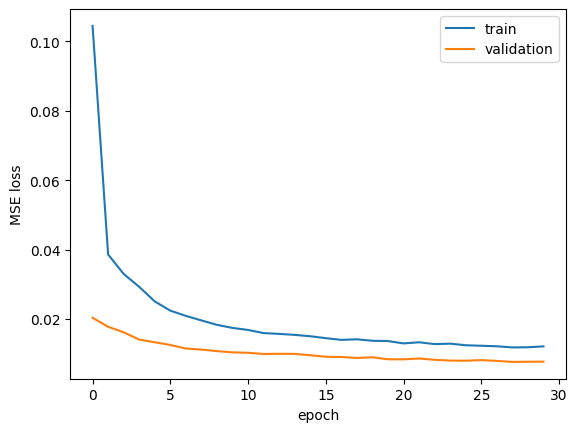

In [5]:
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

hist = model.fit(
    Xtr, Xtr,                        # input = target (it learns to rebuild itself)
    validation_data=(Xva, Xva),
    epochs=30, batch_size=256,
    callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
    verbose=2)

model.save('/content/drive/MyDrive/lstm_ae.keras')   # safe copy in Drive

plt.plot(hist.history['loss'], label='train')
plt.plot(hist.history['val_loss'], label='validation')
plt.xlabel('epoch'); plt.ylabel('MSE loss'); plt.legend(); plt.show()

In [2]:
try:
    print(Xva.shape, Xte.shape, model.name)
except NameError as e:
    print("Session was reset ->", e)

Session was reset -> name 'Xva' is not defined


In [3]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd, numpy as np
from sklearn.preprocessing import StandardScaler
from numpy.lib.stride_tricks import sliding_window_view
df = pd.read_parquet('/content/drive/MyDrive/m100_reduced.parquet')
print(df.shape)

Mounted at /content/drive
(751363, 25)


In [4]:
W = 24
feat = [c for c in df.columns if c not in ('timestamp', 'node', 'label', 'sensor_na', 'lab', 'split')]
df = df.sort_values(['node', 'timestamp']).reset_index(drop=True)
df['lab'] = df['label'].fillna(-1).astype('int8')
df[feat] = df.groupby('node')[feat].ffill(limit=4)

df['split'] = ''
for n, g in df.groupby('node'):
    k1, k2 = int(0.7 * len(g)), int(0.8 * len(g))
    df.loc[g.index[:k1], 'split'] = 'train'
    df.loc[g.index[k1:k2], 'split'] = 'val'
    df.loc[g.index[k2:], 'split'] = 'test'

fit_rows = df[(df.split == 'train') & (df.lab == 0)].dropna(subset=feat)
scaler = StandardScaler().fit(fit_rows[feat])
df[feat] = np.clip(scaler.transform(df[feat]), -5, 5).astype('float32')

def make_windows(split, stride):
    X, y, nodes_ = [], [], []
    for n, g in df[df.split == split].groupby('node'):
        if len(g) < W: continue
        F = g[feat].to_numpy(dtype='float32'); L = g['lab'].to_numpy()
        T = ((g['timestamp'] - g['timestamp'].iloc[0]).dt.total_seconds() / 60).to_numpy()
        Fw = sliding_window_view(F, (W, F.shape[1]))[:, 0]
        Lw = sliding_window_view(L, W); Tw = sliding_window_view(T, W)
        keep = (~np.isnan(Fw).any(axis=(1, 2))
                & ((Tw[:, -1] - Tw[:, 0]) == (W - 1) * 15)
                & np.isin(Lw, [0, 2]).all(axis=1))
        sel = np.zeros_like(keep); sel[::stride] = True; keep &= sel
        X.append(Fw[keep]); y.append((Lw[keep] == 2).any(axis=1)); nodes_.append(np.full(keep.sum(), n))
    return np.concatenate(X), np.concatenate(y), np.concatenate(nodes_)

Xtr, ytr, ntr = make_windows('train', 4); Xtr = Xtr[~ytr]
Xva, yva, nva = make_windows('val', 4);   Xva = Xva[~yva]
Xte, yte, nte = make_windows('test', 2)

print(Xtr.shape, Xva.shape, Xte.shape, int(yte.sum()))

(101924, 24, 22) (17926, 24, 22) (72252, 24, 22) 761


In [5]:
  import tensorflow as tf
  from tensorflow import keras
  model = keras.models.load_model('/content/drive/MyDrive/lstm_ae.keras')
  print(model.name)

sequential


In [6]:
from sklearn.metrics import roc_auc_score, average_precision_score

def window_error(X, bs=1024):
    R = model.predict(X, batch_size=bs, verbose=0)
    return np.mean((X - R) ** 2, axis=(1, 2))   # one number per window

err_va = window_error(Xva)
err_te = window_error(Xte)

print("validation error percentiles (50/90/95/99/99.9):",
      np.percentile(err_va, [50, 90, 95, 99, 99.9]).round(4))
print("test NORMAL  median error:", np.median(err_te[~yte]).round(4))
print("test ANOMALY median error:", np.median(err_te[yte]).round(4))
print("ROC-AUC:", round(roc_auc_score(yte, err_te), 4))
print("PR-AUC :", round(average_precision_score(yte, err_te), 4),
      "(random guessing gives about", round(float(yte.mean()), 4), ")")

validation error percentiles (50/90/95/99/99.9): [0.0023 0.0048 0.0085 0.1321 0.9676]
test NORMAL  median error: 0.0027
test ANOMALY median error: 0.0503
ROC-AUC: 0.787
PR-AUC : 0.0581 (random guessing gives about 0.0105 )


In [7]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

thresholds = {
    "95th percentile": np.percentile(err_va, 95),
    "99th percentile": np.percentile(err_va, 99),
    "mean + 3 std":    err_va.mean() + 3 * err_va.std(),
}
rows = []
for name, thr in thresholds.items():
    pred = err_te > thr
    p, r, f1, _ = precision_recall_fscore_support(yte, pred, average='binary', zero_division=0)
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    rows.append([name, round(float(thr), 4), round(p, 3), round(r, 3), round(f1, 3), fp, fn, tp])
res = pd.DataFrame(rows, columns=['threshold', 'value', 'precision', 'recall', 'F1',
                                  'false_pos', 'false_neg', 'true_pos'])
print(res.to_string(index=False))

      threshold  value  precision  recall    F1  false_pos  false_neg  true_pos
95th percentile 0.0085      0.034   0.594 0.064      12925        309       452
99th percentile 0.1321      0.062   0.329 0.105       3752        511       250
   mean + 3 std 0.1656      0.080   0.323 0.128       2822        515       246


In [8]:
rows = []
for n in np.unique(nte):
    m = nte == n
    if yte[m].sum() == 0: continue
    rows.append([int(n), int(m.sum()), int(yte[m].sum()),
                 round(roc_auc_score(yte[m], err_te[m]), 3),
                 round(average_precision_score(yte[m], err_te[m]), 3),
                 round(float(yte[m].mean()), 3)])
print(pd.DataFrame(rows, columns=['node', 'windows', 'anomalous', 'ROC-AUC',
                                  'PR-AUC', 'random_PR']).to_string(index=False))

 node  windows  anomalous  ROC-AUC  PR-AUC  random_PR
    7     8135         55    0.720   0.017      0.007
    8     7943         34    0.625   0.018      0.004
    9     8134         40    0.699   0.202      0.005
   10     8117        428    0.872   0.251      0.053
   11     8135         41    0.626   0.023      0.005
   13     7944         34    0.706   0.068      0.004
   14     8135         41    0.625   0.057      0.005
   16     7765         54    0.773   0.041      0.007
   17     7944         34    0.779   0.074      0.004


In [9]:
from sklearn.ensemble import IsolationForest

flat = lambda X: X.reshape(len(X), -1)
iso = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1).fit(flat(Xtr))
iso_va = -iso.score_samples(flat(Xva))     # higher = more unusual
iso_te = -iso.score_samples(flat(Xte))

print("Isolation Forest  ROC-AUC:", round(roc_auc_score(yte, iso_te), 4),
      " PR-AUC:", round(average_precision_score(yte, iso_te), 4))
print("LSTM autoencoder  ROC-AUC:", round(roc_auc_score(yte, err_te), 4),
      " PR-AUC:", round(average_precision_score(yte, err_te), 4))

rows = []
for name, thr in {"95th percentile": np.percentile(iso_va, 95),
                  "99th percentile": np.percentile(iso_va, 99),
                  "mean + 3 std": iso_va.mean() + 3 * iso_va.std()}.items():
    pred = iso_te > thr
    p, r, f1, _ = precision_recall_fscore_support(yte, pred, average='binary', zero_division=0)
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    rows.append([name, round(float(thr), 4), round(p, 3), round(r, 3), round(f1, 3), fp, fn, tp])
print(pd.DataFrame(rows, columns=['threshold', 'value', 'precision', 'recall', 'F1',
                                  'false_pos', 'false_neg', 'true_pos']).to_string(index=False))

Isolation Forest  ROC-AUC: 0.6447  PR-AUC: 0.2748
LSTM autoencoder  ROC-AUC: 0.787  PR-AUC: 0.0581
      threshold  value  precision  recall    F1  false_pos  false_neg  true_pos
95th percentile 0.3866      0.021   0.489 0.040      17567        389       372
99th percentile 0.4125      0.028   0.455 0.052      12217        415       346
   mean + 3 std 0.4136      0.028   0.455 0.054      11796        415       346


In [10]:
# 1) How precise is each model among its highest-scoring windows?
def prec_at_k(score, k):
    idx = np.argsort(score)[::-1][:k]
    return round(float(yte[idx].mean()), 3)
print("Precision among top-K scored windows")
for k in (50, 100, 500, 1000):
    print(f"  top {k:>4}:  LSTM {prec_at_k(err_te, k)}   IsoForest {prec_at_k(iso_te, k)}")

# 2) Per-node results for both models
rows = []
for n in np.unique(nte):
    m = nte == n
    if yte[m].sum() == 0: continue
    rows.append([int(n),
                 round(roc_auc_score(yte[m], err_te[m]), 3), round(average_precision_score(yte[m], err_te[m]), 3),
                 round(roc_auc_score(yte[m], iso_te[m]), 3), round(average_precision_score(yte[m], iso_te[m]), 3)])
print("\nPer node")
print(pd.DataFrame(rows, columns=['node', 'LSTM_ROC', 'LSTM_PR', 'IF_ROC', 'IF_PR']).to_string(index=False))

# 3) Drift check: average scaled sensor value on normal rows in each split
print("\nMean scaled value of normal rows per split (0 = same as training)")
print(df[df.lab == 0].groupby('split')[['ambient', 'total_power', 'fan0_0',
                                        'p0_core_temp', 'gpu_core_temp']].mean().round(2))

Precision among top-K scored windows
  top   50:  LSTM 0.24   IsoForest 1.0
  top  100:  LSTM 0.15   IsoForest 1.0
  top  500:  LSTM 0.06   IsoForest 0.386
  top 1000:  LSTM 0.038   IsoForest 0.199

Per node
 node  LSTM_ROC  LSTM_PR  IF_ROC  IF_PR
    7     0.720    0.017   0.521  0.008
    8     0.625    0.018   0.590  0.005
    9     0.699    0.202   0.619  0.011
   10     0.872    0.251   0.797  0.578
   11     0.626    0.023   0.554  0.006
   13     0.706    0.068   0.431  0.004
   14     0.625    0.057   0.603  0.009
   16     0.773    0.041   0.519  0.013
   17     0.779    0.074   0.551  0.006

Mean scaled value of normal rows per split (0 = same as training)
       ambient  total_power  fan0_0  p0_core_temp  gpu_core_temp
split                                                           
test     -0.49        -0.07   -0.16         -0.22          -0.35
train    -0.00        -0.01   -0.04         -0.00          -0.00
val      -0.51        -0.14   -0.14         -0.26          -0.46


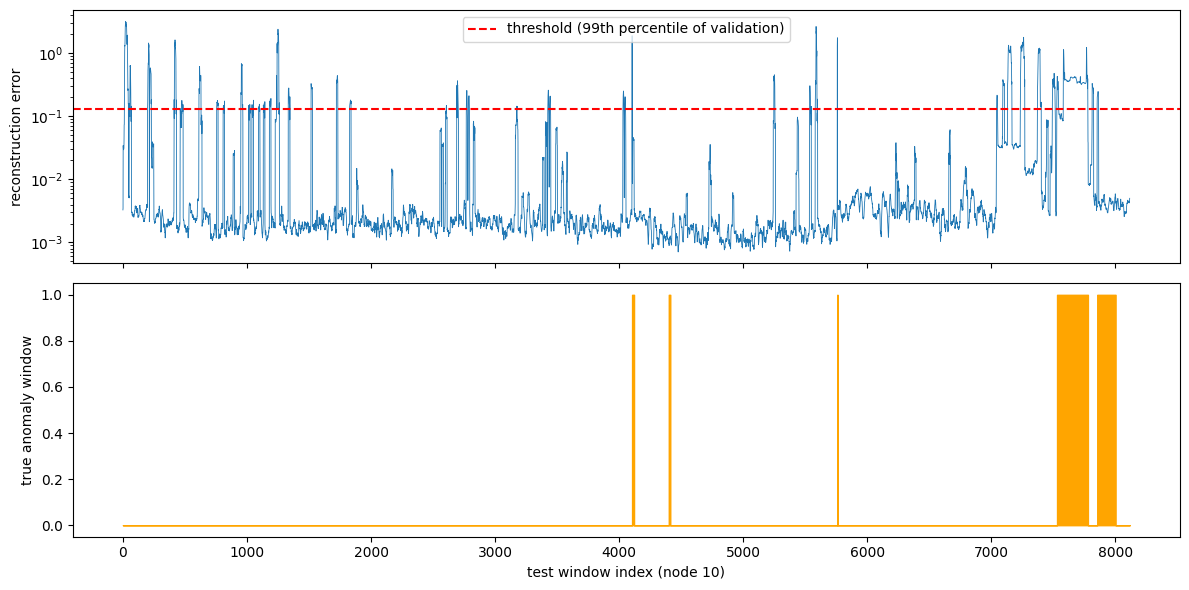

In [11]:
import matplotlib.pyplot as plt

thr99 = np.percentile(err_va, 99)
m = nte == 10
e, y = err_te[m], yte[m]

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(e, lw=0.6)
ax[0].axhline(thr99, color='r', ls='--', label='threshold (99th percentile of validation)')
ax[0].set_yscale('log'); ax[0].set_ylabel('reconstruction error'); ax[0].legend()
ax[1].fill_between(range(len(y)), y.astype(int), step='mid', color='orange')
ax[1].set_ylabel('true anomaly window'); ax[1].set_xlabel('test window index (node 10)')
plt.tight_layout(); plt.show()

In [12]:
fig.savefig('/content/drive/MyDrive/node10_error_plot.png', dpi=200, bbox_inches='tight')
res.to_csv('/content/drive/MyDrive/lstm_threshold_results.csv', index=False)
np.savez('/content/drive/MyDrive/scores.npz', err_va=err_va, err_te=err_te,
         iso_va=iso_va, iso_te=iso_te, yte=yte, nte=nte)
print('saved')

saved


In [13]:
def runs(flag, node):
    """(start, end) index pairs of consecutive True values within the same node"""
    out, i, n = [], 0, len(flag)
    while i < n:
        if flag[i]:
            j = i
            while j + 1 < n and flag[j + 1] and node[j + 1] == node[i]:
                j += 1
            out.append((i, j))
            i = j + 1
        else:
            i += 1
    return out

def event_report(thr, score):
    pred = score > thr
    episodes = runs(yte, nte)
    alarms = runs(pred, nte)
    detected = int(sum(pred[s:e + 1].any() for s, e in episodes))
    true_bursts = int(sum(yte[s:e + 1].any() for s, e in alarms))
    return {'episodes': len(episodes), 'detected': detected,
            'event_recall': round(detected / len(episodes), 3),
            'alarm_bursts': len(alarms), 'false_bursts': len(alarms) - true_bursts,
            'burst_precision': round(true_bursts / max(len(alarms), 1), 3)}

rows = []
for mname, s_va, s_te in [("LSTM-AE", err_va, err_te), ("IsoForest", iso_va, iso_te)]:
    for tname, thr in {"95th pct": np.percentile(s_va, 95),
                       "99th pct": np.percentile(s_va, 99),
                       "mean+3std": s_va.mean() + 3 * s_va.std()}.items():
        r = event_report(thr, s_te)
        rows.append([mname, tname] + list(r.values()))
print(pd.DataFrame(rows, columns=['model', 'threshold'] + list(r.keys())).to_string(index=False))

print("\nEpisodes per node (length = number of windows)")
for n in np.unique(nte):
    idx = np.flatnonzero(nte == n)
    ep = runs(yte[idx], nte[idx])
    print(int(n), "episodes:", len(ep), " lengths:", [e - s + 1 for s, e in ep])

    model threshold  episodes  detected  event_recall  alarm_bursts  false_bursts  burst_precision
  LSTM-AE  95th pct        31        23         0.742           619           593            0.042
  LSTM-AE  99th pct        31        14         0.452           483           468            0.031
  LSTM-AE mean+3std        31        13         0.419           382           368            0.037
IsoForest  95th pct        31        18         0.581           697           682            0.022
IsoForest  99th pct        31        13         0.419           735           722            0.018
IsoForest mean+3std        31        13         0.419           689           676            0.019

Episodes per node (length = number of windows)
7 episodes: 4  lengths: [17, 12, 14, 12]
8 episodes: 3  lengths: [16, 6, 12]
9 episodes: 3  lengths: [16, 12, 12]
10 episodes: 5  lengths: [16, 12, 3, 249, 148]
11 episodes: 3  lengths: [17, 12, 12]
13 episodes: 3  lengths: [17, 5, 12]
14 episodes: 3  lengths

In [14]:
import json

def window_end_times(split='test', stride=2):
    t_end, nodes_ = [], []
    for n, g in df[df.split == split].groupby('node'):
        if len(g) < W: continue
        F = g[feat].to_numpy(dtype='float32'); L = g['lab'].to_numpy()
        T = ((g['timestamp'] - g['timestamp'].iloc[0]).dt.total_seconds() / 60).to_numpy()
        Fw = sliding_window_view(F, (W, F.shape[1]))[:, 0]
        Lw = sliding_window_view(L, W); Tw = sliding_window_view(T, W)
        keep = (~np.isnan(Fw).any(axis=(1, 2))
                & ((Tw[:, -1] - Tw[:, 0]) == (W - 1) * 15)
                & np.isin(Lw, [0, 2]).all(axis=1))
        sel = np.zeros_like(keep); sel[::stride] = True; keep &= sel
        ts_w = sliding_window_view(g['timestamp'].to_numpy(), W)
        t_end.append(ts_w[keep][:, -1]); nodes_.append(np.full(keep.sum(), n))
    return np.concatenate(t_end), np.concatenate(nodes_)

t_end, n_chk = window_end_times()
assert len(t_end) == len(Xte) and (n_chk == nte).all(), "window order mismatch"

last = scaler.inverse_transform(Xte[:, -1, :])          # last time step of each window, back to original units
dash = pd.DataFrame(last, columns=feat)
dash.insert(0, 'node', nte)
dash.insert(1, 'time', pd.to_datetime(t_end))
dash['score_lstm'] = err_te
dash['score_if'] = iso_te
dash['is_anomaly'] = yte.astype(int)
dash.to_parquet('/content/drive/MyDrive/dashboard_data.parquet')

thr = {}
for tag, s in [('lstm', err_va), ('if', iso_va)]:
    thr[f'{tag}_95'] = float(np.percentile(s, 95))
    thr[f'{tag}_99'] = float(np.percentile(s, 99))
    thr[f'{tag}_mean3std'] = float(s.mean() + 3 * s.std())
json.dump(thr, open('/content/drive/MyDrive/thresholds.json', 'w'), indent=2)

ev_rows = []
for mname, s_va, s_te in [("LSTM-AE", err_va, err_te), ("IsoForest", iso_va, iso_te)]:
    for tname, t in {"95th pct": np.percentile(s_va, 95), "99th pct": np.percentile(s_va, 99),
                     "mean+3std": s_va.mean() + 3 * s_va.std()}.items():
        ev_rows.append({'model': mname, 'threshold': tname, **event_report(t, s_te)})
pd.DataFrame(ev_rows).to_csv('/content/drive/MyDrive/event_level_results.csv', index=False)

print(dash.shape); print(dash[['node', 'time', 'score_lstm', 'is_anomaly']].head(3))

(72252, 27)
   node                      time  score_lstm  is_anomaly
0     7 2022-04-07 07:45:00+00:00    0.001924           0
1     7 2022-04-07 08:15:00+00:00    0.002718           0
2     7 2022-04-07 08:45:00+00:00    0.057280           0
